In [1]:
import numpy as np

class Q_Learning:
    # Конструктор класса Q_Learning, который отвечает за инициализацию параметров обучения.
    def __init__(self, env, alpha, gamma, epsilon, numberEpisodes, numberOfBins, lowerBounds, upperBounds):
        import numpy as np

        # Сохраняем переданные параметры:
        self.env = env  # Среда для обучения (например, CartPole)
        self.alpha = alpha  # Коэффициент обучения
        self.gamma = gamma  # Коэффициент дисконтирования будущих наград
        self.epsilon = epsilon  # Вероятность выбора случайного действия (ε-жадная стратегия)
        self.actionNumber = env.action_space.n  # Количество возможных действий в среде
        self.numberEpisodes = numberEpisodes  # Количество эпизодов для обучения
        self.numberOfBins = numberOfBins  # Количество интервалов для дискретизации состояний
        self.lowerBounds = lowerBounds  # Нижние границы состояний среды
        self.upperBounds = upperBounds  # Верхние границы состояний среды

        self.sumRewardsEpisode = []  # Список для хранения суммарных наград за эпизоды

        # Создание Q-таблицы, заполняем случайными значениями от 0 до 1
        # Таблица имеет размерность (кол-во интервалов для каждого состояния, кол-во действий)
        self.Qmatrix = np.random.uniform(
            low=0, high=1, size=(
                numberOfBins[0], numberOfBins[1], numberOfBins[2], numberOfBins[3], self.actionNumber
            )
        )

    # Метод преобразует непрерывное состояние в индекс в Q-таблице.
    def returnIndexState(self, state):
        position = state[0]  # Позиция тележки
        velocity = state[1]  # Скорость тележки
        angle = state[2]  # Угол наклона шеста
        angularVelocity = state[3]  # Угловая скорость шеста

        # Дискретизируем каждую переменную состояния, разбивая ее на интервалы (bins)
        cartPositionBin = np.linspace(self.lowerBounds[0], self.upperBounds[0], self.numberOfBins[0])
        cartVelocityBin = np.linspace(self.lowerBounds[1], self.upperBounds[1], self.numberOfBins[1])
        poleAngleBin = np.linspace(self.lowerBounds[2], self.upperBounds[2], self.numberOfBins[2])
        poleAngleVelocityBin = np.linspace(self.lowerBounds[3], self.upperBounds[3], self.numberOfBins[3])

        # Получаем индексы состояний, соответствующие интервалам
        indexPosition = np.maximum(np.digitize(state[0], cartPositionBin) - 1, 0)
        indexVelocity = np.maximum(np.digitize(state[1], cartVelocityBin) - 1, 0)
        indexAngle = np.maximum(np.digitize(state[2], poleAngleBin) - 1, 0)
        indexAngularVelocity = np.maximum(np.digitize(state[3], poleAngleVelocityBin) - 1, 0)

        return tuple([indexPosition, indexVelocity, indexAngle, indexAngularVelocity])

    # Метод выбора действия с использованием ε-жадной стратегии
    def selectAction(self, state, index):
        if index < 500:
            return np.random.choice(self.actionNumber)  # Выбираем случайное действие на первых 500 итерациях

        randomNumber = np.random.random()  # Генерируем случайное число

        # Постепенно уменьшаем ε после 7000 итераций, чтобы снижать уровень случайности
        if index > 7000:
            self.epsilon = 0.999 * self.epsilon

        if randomNumber < self.epsilon:
            return np.random.choice(self.actionNumber)  # Случайный выбор действия с вероятностью ε
        else:
            # Выбираем действие с максимальным Q-значением в текущем состоянии
            return np.random.choice(np.where(
                self.Qmatrix[self.returnIndexState(state)] == np.max(self.Qmatrix[self.returnIndexState(state)])
            )[0])

    # Метод для обучения агента путем симуляции эпизодов
    def simulateEpisodes(self):
        import numpy as np

        for indexEpisode in range(self.numberEpisodes):
            rewardsEpisode = []  # Храним награды за эпизод

            (stateS, _) = self.env.reset()  # Инициализируем среду
            stateS = list(stateS)  # Преобразуем состояние в список

            print("Simulating episode {}".format(indexEpisode))

            terminalState = False  # Флаг завершения эпизода
            while not terminalState:
                stateSIndex = self.returnIndexState(stateS)  # Получаем индексы состояния

                actionA = self.selectAction(stateS, indexEpisode)  # Выбираем действие

                # Выполняем действие в среде и получаем новую информацию
                (stateSprime, reward, terminalState, _, _) = self.env.step(actionA)

                rewardsEpisode.append(reward)  # Сохраняем награду за текущее действие

                stateSprime = list(stateSprime)
                stateSprimeIndex = self.returnIndexState(stateSprime)

                QmaxPrime = np.max(self.Qmatrix[stateSprimeIndex])  # Максимальное Q-значение для нового состояния

                if not terminalState:
                    error = reward + self.gamma * QmaxPrime - self.Qmatrix[stateSIndex + (actionA,)]
                else:
                    error = reward - self.Qmatrix[stateSIndex + (actionA,)]

                # Обновляем Q-значение с использованием Q-learning формулы
                self.Qmatrix[stateSIndex + (actionA,)] += self.alpha * error

                stateS = stateSprime  # Переход в новое состояние

            print("Sum of rewards {}".format(np.sum(rewardsEpisode)))
            self.sumRewardsEpisode.append(np.sum(rewardsEpisode))

    # Симуляция работы обученного агента
    def simulateLearnedStrategy(self):
        import gymnasium as gym
        import time
        env1 = gym.make('CartPole-v1', render_mode='human')
        (currentState, _) = env1.reset()
        env1.render()
        timeSteps = 1000
        obtainedRewards = []

        for timeIndex in range(timeSteps):
            print(timeIndex)

            # Выбираем лучшее действие на основе Q-значений
            actionInStateS = np.random.choice(np.where(
                self.Qmatrix[self.returnIndexState(currentState)] == np.max(
                    self.Qmatrix[self.returnIndexState(currentState)]
                )
            )[0])

            currentState, reward, terminated, truncated, info = env1.step(actionInStateS)
            obtainedRewards.append(reward)
            time.sleep(0.05)
            if terminated:
                time.sleep(1)
                break
        return obtainedRewards, env1

    # Симуляция случайного агента для сравнения с обученной стратегией
    def simulateRandomStrategy(self):
        import gymnasium as gym
        import time
        import numpy as np
        env2 = gym.make('CartPole-v1')
        (currentState, _) = env2.reset()
        env2.render()

        episodeNumber = 100  # Количество эпизодов
        timeSteps = 1000  # Максимальная длина эпизода
        sumRewardsEpisodes = []

        for episodeIndex in range(episodeNumber):
            rewardsSingleEpisode = []
            print(episodeIndex)
            for timeIndex in range(timeSteps):
                random_action = env2.action_space.sample()  # Выбираем случайное действие
                observation, reward, terminated, truncated, info = env2.step(random_action)
                rewardsSingleEpisode.append(reward)
                if terminated:
                    break
            sumRewardsEpisodes.append(np.sum(rewardsSingleEpisode))
        return sumRewardsEpisodes, env2

Выходные данные были обрезаны до нескольких последних строк (5000).
Simulating episode 12558
Sum of rewards 195.0
Simulating episode 12559
Sum of rewards 199.0
Simulating episode 12560
Sum of rewards 220.0
Simulating episode 12561
Sum of rewards 128.0
Simulating episode 12562
Sum of rewards 125.0
Simulating episode 12563
Sum of rewards 220.0
Simulating episode 12564
Sum of rewards 124.0
Simulating episode 12565
Sum of rewards 165.0
Simulating episode 12566
Sum of rewards 150.0
Simulating episode 12567
Sum of rewards 173.0
Simulating episode 12568
Sum of rewards 199.0
Simulating episode 12569
Sum of rewards 224.0
Simulating episode 12570
Sum of rewards 160.0
Simulating episode 12571
Sum of rewards 209.0
Simulating episode 12572
Sum of rewards 188.0
Simulating episode 12573
Sum of rewards 137.0
Simulating episode 12574
Sum of rewards 284.0
Simulating episode 12575
Sum of rewards 257.0
Simulating episode 12576
Sum of rewards 200.0
Simulating episode 12577
Sum of rewards 209.0
Simulating e

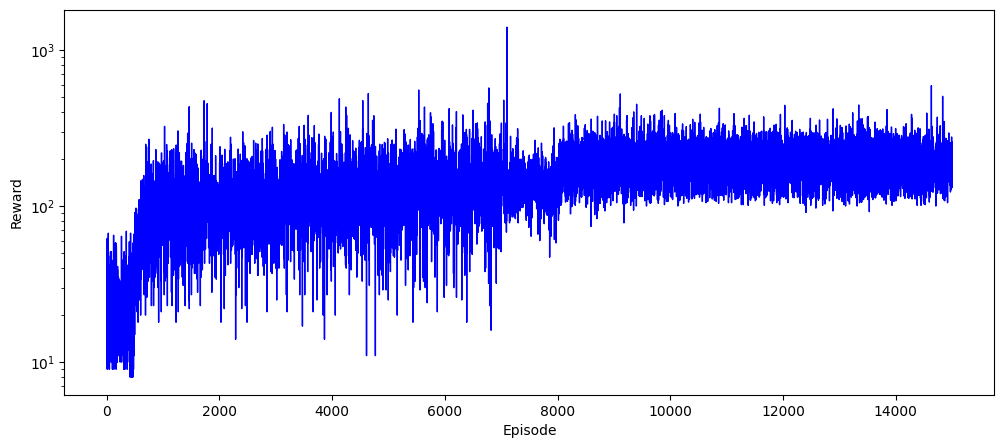

/usr/local/lib/python3.11/dist-packages/gymnasium/envs/classic_control/cartpole.py:250: UserWarning: WARN: You are calling render method without specifying any render mode. You can specify the render_mode at initialization, e.g. gym.make("CartPole-v1", render_mode="rgb_array")
  gym.logger.warn(


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


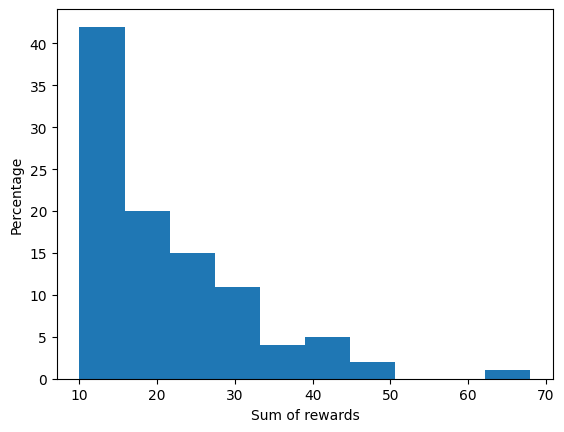

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151


In [ ]:
import gymnasium as gym
import numpy as np
import time
import matplotlib.pyplot as plt

# Создание окружения CartPole-v1
env = gym.make('CartPole-v1')
(state, _) = env.reset()  # Сброс окружения и получение начального состояния

# Установление пределов наблюдений (состояний)
upperBounds = env.observation_space.high  # Верхние границы состояний
lowerBounds = env.observation_space.low  # Нижние границы состояний

# Ограничения для скорости тележки и угловой скорости шеста
cartVelocityMin = -3  # Минимальная скорость тележки
cartVelocityMax = 3  # Максимальная скорость тележки
poleAngleVelocityMin = -10  # Минимальная угловая скорость шеста
poleAngleVelocityMax = 10  # Максимальная угловая скорость шеста

# Корректировка верхних и нижних границ состояний с учетом заданных ограничений
upperBounds[1] = cartVelocityMax
upperBounds[3] = poleAngleVelocityMax
lowerBounds[1] = cartVelocityMin
lowerBounds[3] = poleAngleVelocityMin

# Определение количества бинов (дискретизация состояний)
numberOfBinsPosition = 30  # Количество бинов для позиции тележки
numberOfBinsVelocity = 30  # Количество бинов для скорости тележки
numberOfBinsAngle = 30  # Количество бинов для угла наклона шеста
numberOfBinsAngleVelocity = 30  # Количество бинов для угловой скорости шеста
numberOfBins = [numberOfBinsPosition, numberOfBinsVelocity, numberOfBinsAngle, numberOfBinsAngleVelocity]

# Гиперпараметры алгоритма Q-Learning
alpha = 0.1  # Скорость обучения
gamma = 1  # Коэффициент дисконтирования
epsilon = 0.2  # Вероятность выбора случайного действия (epsilon-жадная стратегия)
numberEpisodes = 15000

# Создание объекта Q-Learning и обучение
Q1 = Q_Learning(env, alpha, gamma, epsilon, numberEpisodes, numberOfBins, lowerBounds, upperBounds)
Q1.simulateEpisodes()

# Симуляция стратегии, полученной после обучения
(obtainedRewardsOptimal, env1) = Q1.simulateLearnedStrategy()

# Построение графика наград по эпизодам
plt.figure(figsize=(12, 5))
plt.plot(Q1.sumRewardsEpisode, color='blue', linewidth=1)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.yscale('log')
plt.show()
plt.savefig('convergence.png')

# Закрытие симуляции
env1.close()

# Вычисление суммы наград за оптимальную стратегию
np.sum(obtainedRewardsOptimal)

# Симуляция случайной стратегии
(obtainedRewardsRandom, env2) = Q1.simulateRandomStrategy()
plt.hist(obtainedRewardsRandom)  # Построение гистограммы наград случайной стратегии
plt.xlabel('Sum of rewards')
plt.ylabel('Percentage')
plt.savefig('histogram.png')
plt.show()

# Повторная симуляция обученной стратегии
(obtainedRewardsOptimal, env1) = Q1.simulateLearnedStrategy()